In [1]:
# Libraries and Packages

# External packages
import sys
from pathlib import Path

import astropy.units as u
import numpy as np
from astropy.coordinates import SkyCoord
from astropy.table import QTable
from astropy.time import Time, TimeDelta
from astroquery.jplhorizons import Horizons
from IPython.display import display
from sora import Body, Observer, Occultation, Star
from sora.ephem import EphemHorizons
from sora.prediction import prediction

# Internal modules / packages
sys.path.append(str(Path.cwd().parent))

from occultations.core.eph import get_eph
from occultations.core.ephem_table import EphemTable

SORA version: 0.3.3


In [2]:
# Hyperparameters

# Inputs
rock = 'Silesia'
obs_id = 'W63'
epoch_jpl = {
  'start': '2019-06-27',
  'stop': '2019-06-29',
  'step': '1m',
  'number': 1000
}
epoch_mpc = {
  'start': '2019-06-27',
  'stop': '2019-06-29',
  'step': '1min',
  'number': 1000
}
mag_lim = 16
exposition_time = 5

# Others
divs = 1      # Divisions in star processing (We'll compute divs as the time interval in days over 30, as it is only really convenient in long periods of time)
step = 10     # Step of ephemerides for predictions in seconds (It must be the same step as the ephemerides generation) (sampling)
sigma = 3     # Amplification factor for the search of predictions (I plan on using 3 because the error_ra and error_dec are going to be the maximum values in the ephem table ('Uncertainty 3sig' over 3 or 'RA_3sigma' and 'DEC_3sigma' over 3). This works as an approximation of the error for the search of predictions.
radius = 100  # Radius of the object (we already found the radius of the object previously, it is only about using it as an argument)

In [3]:
# Body instantiation
body = Body(rock)

# Observer instantiation
obs = Observer(name=obs_id, code=obs_id)

# Times
time_start = Time(epoch_jpl['start'], scale='utc')
time_stop = Time(epoch_jpl['stop'], scale='utc')

# Horizons observer location (same convention used by SORA)
location = f'{obs.code}@{obs.spkid}'

print("Horizons location:", location)
print("Horizons epochs:", epoch_jpl)

Obtaining data for Silesia from SBDB


d:\Users\andre\Escritorio\Universal\Code\Python\projects\occ\.venv\Lib\site-packages\sora\observer\utils.py:48: UserWarning: Querying code W63 in the Linea MPC Observer Database...
  warnings.warn(f'Querying code {code} in the Linea MPC Observer Database...')


Horizons location: W63@399
Horizons epochs: {'start': '2019-06-27', 'stop': '2019-06-29', 'step': '1m', 'number': 1000}


In [4]:
# Function to get topocentric ephemerides from JPL
def jpl_eph_topo(body, epoch, obs_id):

  # Convert epoch if necessary
  if isinstance(epoch, dict) and epoch.get('number') == 1:
    epoch = Time(epoch['start']).jd

  elif isinstance(epoch, list) and not isinstance(epoch[0], float):
    epoch = Time(epoch).jd

  # Get topocentric ephemerides
  body = Horizons(
    id=body,
    location=obs_id,
    epochs=epoch
  )

  eph = body.ephemerides(extra_precision=True, cache=False)

  # Expected uncertainty columns
  unc_cols = [
    'RA_3sigma', 'DEC_3sigma',
    'SMAA_3sigma', 'SMIA_3sigma',
    'Theta_3sigma'
  ]

  if all(col in eph.colnames for col in unc_cols):

    data = eph[
      'datetime_jd', 'RA', 'DEC', 'delta',
      'RA_3sigma', 'DEC_3sigma',
      'SMAA_3sigma', 'SMIA_3sigma',
      'Theta_3sigma'
    ]

    if all(data['RA_3sigma'].mask):
      print('Uncertainty is masked, orbit solution might only be nominal.')
      data = eph['datetime_jd', 'RA', 'DEC', 'delta']

  else:
    print('Ephemeris uncertainty is not available.')
    data = eph['datetime_jd', 'RA', 'DEC', 'delta']

  # Rename columns
  data.rename_columns(
    ['datetime_jd', 'RA', 'DEC', 'delta'],
    ['time', 'ra', 'dec', 'distance']
  )

  # Assign units
  data['time'].unit = u.d
  data['ra'].unit = u.deg
  data['dec'].unit = u.deg
  data['distance'].unit = u.au

  return data

In [5]:
# Query topocentric ephemeris
eph_topo = jpl_eph_topo(rock, epoch_jpl, obs_id)

display(eph_topo[:5])

time,ra,dec,distance,RA_3sigma,DEC_3sigma,SMAA_3sigma,SMIA_3sigma,Theta_3sigma
d,deg,deg,AU,arcsec,arcsec,arcsec,arcsec,deg
float64,float64,float64,float64,float64,float64,float64,float64,float64
2458661.5,275.354174279,-27.835736264,2.39811627674003,0.002,0.001,0.00188,0.00079,-7.547
2458661.500694444,275.354021963,-27.835748053,2.39811572172754,0.002,0.001,0.00188,0.00079,-7.547
2458661.501388889,275.353869625,-27.835759838,2.39811516702472,0.002,0.001,0.00188,0.00079,-7.547
2458661.502083333,275.353717265,-27.835771621,2.39811461263462,0.002,0.001,0.00188,0.00079,-7.547
2458661.502777778,275.353564884,-27.835783401,2.39811405856029,0.002,0.001,0.00188,0.00079,-7.547


In [6]:
# Create EphemTable using topocentric JPL ephemerides
body_topo = EphemTable(
    table=eph_topo,
    name=rock
)

In [14]:
# Inspect ephemeris objects

print('=== body_topo ===')
print('Type:', type(body_topo))
print(body_topo)

print('\n=== eph_topo ===')
print('Type:', type(eph_topo))

if hasattr(eph_topo, 'colnames'):
    print('Columns:', eph_topo.colnames)
elif hasattr(eph_topo, 'columns'):
    print('Columns:', eph_topo.columns)
else:
    print('Attributes:', [x for x in dir(eph_topo) if not x.startswith('_')])

print('\n=== Available body_topo attributes ===')
print([x for x in dir(body_topo) if not x.startswith('_')])

=== body_topo ===
Type: <class 'occultations.core.ephem_table.EphemTable'>
----------- Ephemeris -----------

EphemTable: {ephem_info} (SPKID=)
Ephem Error: RA*cosDEC: 0.000 arcsec; DEC: 0.000 arcsec
Offset applied: RA*cosDEC: 0.0000 arcsec; DEC: 0.0000 arcsec


=== eph_topo ===
Type: <class 'astropy.table.table.Table'>
Columns: ['time', 'ra', 'dec', 'distance', 'RA_3sigma', 'DEC_3sigma', 'SMAA_3sigma', 'SMIA_3sigma', 'Theta_3sigma', 'ra_sin', 'ra_cos']

=== Available body_topo attributes ===
['G', 'H', 'add_offset', 'apparent_magnitude', 'error_dec', 'error_ra', 'get_ksi_eta', 'get_pole_position_angle', 'get_position', 'mass', 'max_time', 'meta', 'min_time', 'name', 'offset', 'radius', 'spkid', 'table', 'to_file']


In [7]:
# Test position at the middle of the interval
time_test = Time('2019-06-28T00:00:00')

position = body_topo.get_position(time_test)

print(position)
print(f"RA: {position.ra.deg:.8f} deg")
print(f"DEC: {position.dec.deg:.8f} deg")
print(f"Distance: {position.distance.au:.8f} AU")

<SkyCoord (ICRS): (ra, dec, distance) in (deg, deg, AU)
    (275.13646955, -27.84938901, 2.39769042)>
RA: 275.13646955 deg
DEC: -27.84938901 deg
Distance: 2.39769042 AU


In [8]:
# Test EphemHorizons position
body_horizons = EphemHorizons(
    name=rock
)

position_horizons = body_horizons.get_position(
    time=time_test,
    observer=obs
)

print(position_horizons)
print(f"RA: {position_horizons.ra.deg:.8f} deg")
print(f"DEC: {position_horizons.dec.deg:.8f} deg")
print(f"Distance: {position_horizons.distance.au:.8f} AU")

<SkyCoord (ICRS): (ra, dec, distance) in (deg, deg, AU)
    (275.13646955, -27.84938901, 2.39769042)>
RA: 275.13646955 deg
DEC: -27.84938901 deg
Distance: 2.39769042 AU


In [9]:
# Topocentric prediction (SORA)
pred_top_sora = prediction(
  time_beg=Time(epoch_jpl['start']),
  time_end=Time(epoch_jpl['stop']),
  body=body,
  reference_center=obs,
  mag_lim=mag_lim,
  divs=divs,
  step=step,
  verbose=True
)

Ephemeris was split in 1 parts for better search of stars

Searching occultations in part 1/1
Generating Ephemeris between 2019-06-27 00:00:00.000 and 2019-06-28 23:59:50.000 ...
    423 GaiaDR3 stars downloaded
Identifying occultations ...

1 occultations found.


In [10]:
# Topocentric prediction (us)
pred_top_table = prediction(
    time_beg=Time(epoch_jpl['start']),
    time_end=Time(epoch_jpl['stop']),
    ephem=body_topo,
    reference_center=obs,
    radius=body.radius,
    mag_lim=mag_lim,
    divs=divs,
    step=step,
    verbose=True
)

Ephemeris was split in 1 parts for better search of stars

Searching occultations in part 1/1
Generating Ephemeris between 2019-06-27 00:00:00.000 and 2019-06-28 23:59:50.000 ...
    423 GaiaDR3 stars downloaded
Identifying occultations ...

1 occultations found.


In [11]:
pred_top_table

Epoch,ICRS Star Coord at Epoch,Geocentric Object Position,C/A,P/A,Vel,Dist,G,long,loct,M-G-T,S-G-T,GaiaDR3 Source ID
,,,arcsec,deg,km / s,AU,mag,deg,hh:mm,deg,deg,
object,object,object,float64,float64,float64,float64,float64,float64,str5,float64,float64,str19
2019-06-28 03:48:10.040,18 20 24.29144 -27 51 06.47524,18 20 24.29148 -27 51 06.48191,0.007,175.87,-14.43,2.398,13.398,302,23:56,122,175,4051506284553476736


In [12]:
pred_top_sora

Epoch,ICRS Star Coord at Epoch,Geocentric Object Position,C/A,P/A,Vel,Dist,G,long,loct,M-G-T,S-G-T,GaiaDR3 Source ID
,,,arcsec,deg,km / s,AU,mag,deg,hh:mm,deg,deg,
object,object,object,float64,float64,float64,float64,float64,float64,str5,float64,float64,str19
2019-06-28 03:48:10.040,18 20 24.29144 -27 51 06.47524,18 20 24.29148 -27 51 06.48191,0.007,175.86,-14.43,2.398,13.398,302,23:56,122,175,4051506284553476736


In [13]:
# Compare topocentric predictions with full precision

print('P/A comparison:')
print(f'Our method: {pred_top_table["P/A"][0]:.10f} deg')
print(f'SORA:       {pred_top_sora["P/A"][0]:.10f} deg')
print(f'Difference: {pred_top_table["P/A"][0] - pred_top_sora["P/A"][0]:.10f} deg')

print('\nVelocity comparison:')
print(f'Our method: {pred_top_table["Vel"][0]:.10f} km/s')
print(f'SORA:       {pred_top_sora["Vel"][0]:.10f} km/s')
print(f'Difference: {pred_top_table["Vel"][0] - pred_top_sora["Vel"][0]:.10f} km/s')

P/A comparison:
Our method: 175.8735203055 deg
SORA:       175.8643153700 deg
Difference: 0.0092049355 deg

Velocity comparison:
Our method: -14.4250353862 km/s
SORA:       -14.4265717901 km/s
Difference: 0.0015364039 km/s


In [27]:
# Extract relevant data from topocentric prediction
star_id = pred_top_sora['GaiaDR3 Source ID'][0]
epoch_occ = pred_top_sora['Epoch'][0]

In [28]:
epoch_occ

<Time object: scale='utc' format='iso' value=2019-06-28 03:48:10.040>

In [ ]:
# Geocentric prediction (SORA)
pred_geo_sora = prediction(
  time_beg=str(epoch_occ - '0.1d'),
  time_end=str(epoch_occ + '0.1d'),
  body=body,
  mag_lim=mag_lim,
  divs=divs,
  step=step,
  sigma=sigma,
  verbose=True
)

Ephemeris was split in 1 parts for better search of stars

Searching occultations in part 1/1
Generating Ephemeris between 2019-06-28 01:24:10.040 and 2019-06-28 06:12:00.040 ...
    12 GaiaDR3 stars downloaded
Identifying occultations ...


d:\Users\andre\Escritorio\Universal\Code\Python\projects\occ\.venv\Lib\site-packages\sora\observer\utils.py:48: UserWarning: Querying code 500 in the Linea MPC Observer Database...
  warnings.warn(f'Querying code {code} in the Linea MPC Observer Database...')



8 occultations found.


In [31]:
# Star instatiation
star = Star(code=star_id, epoch=epoch_occ)

print('Identifying Occultation...')
for i in pred_geo_sora:
  if i[12] == star.code:
    pred_geo_sora = i
    print('Occultation identified!')
    break

# # Occultation instantiation
# occ = Occultation(
#   body=body,
#   star=star,
#   time=epoch_occ,
#   reference_center=obs
# )

1 GaiaDR3 (LIneA TAP: gaia_dr3.source) star found band={'G': 13.397762298583984}
star coordinate at J2016.0: RA=18h20m24.29259s +/- 0.019742164760828018 deg, DEC=-27d51m06.4713s +/- 0.016225365921854973 deg

Identifying Occultation...
Occultation identified!


In [32]:
pred_geo_sora

Epoch,ICRS Star Coord at Epoch,Geocentric Object Position,C/A,P/A,Vel,Dist,G,long,loct,M-G-T,S-G-T,GaiaDR3 Source ID
,,,arcsec,deg,km / s,AU,mag,deg,hh:mm,deg,deg,
object,object,object,float64,float64,float64,float64,float64,float64,str5,float64,float64,str19
2019-06-28 03:46:05.580,18 20 24.29144 -27 51 06.47524,18 20 23.40220 -27 51 05.31109,1.960,356.11,-13.98,2.398,13.398,303,23:56,122,175,4051506284553476736


In [50]:
obs.lon.value

np.float64(-75.69042000000002)

Silesia_map_geo.png generated


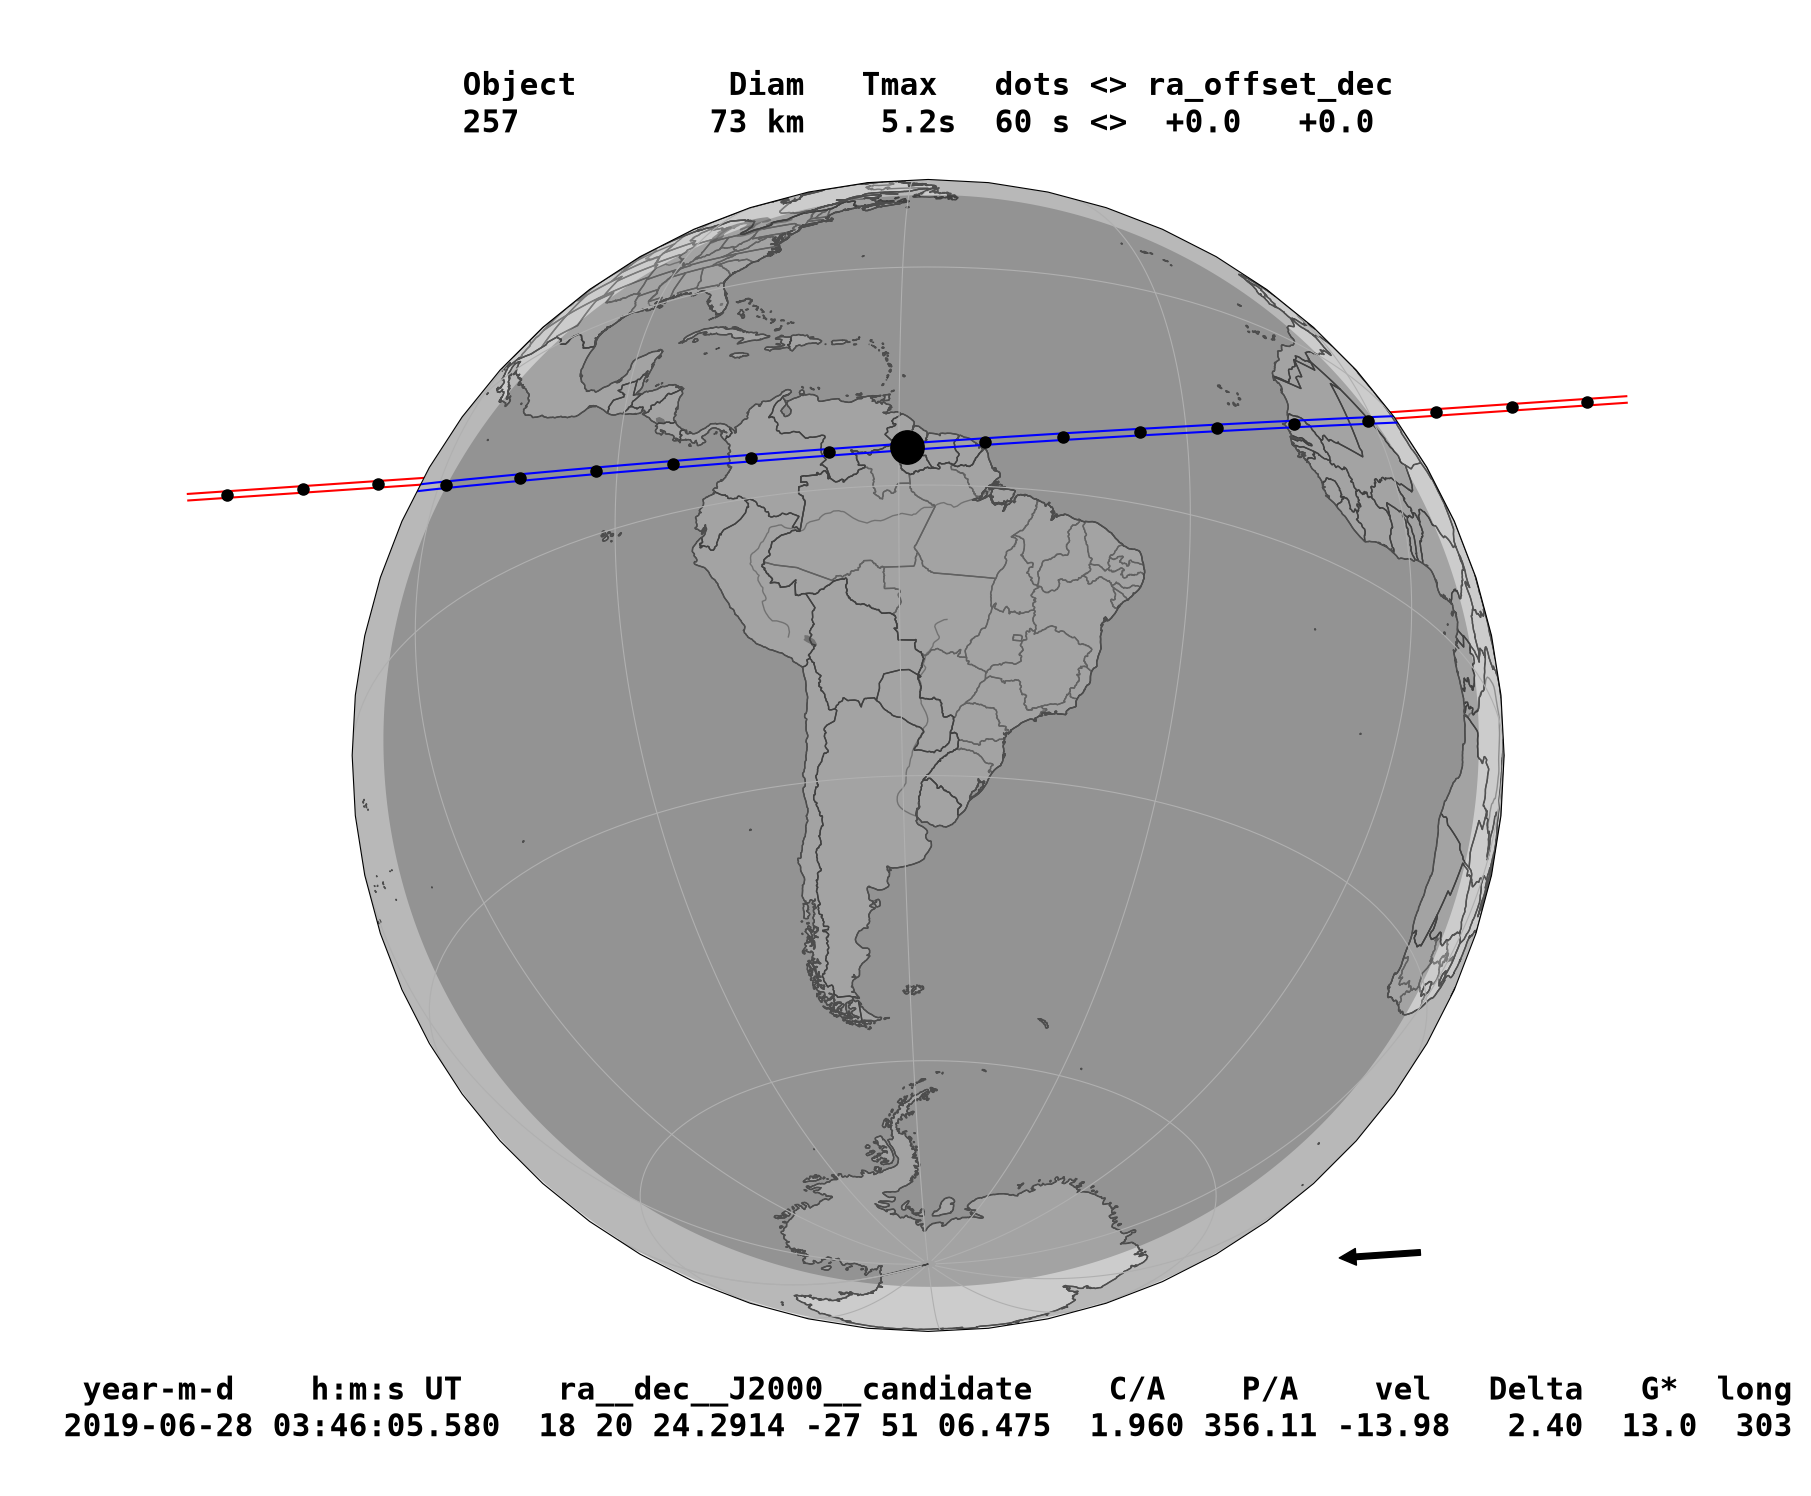

In [55]:
# Occultation map
pred_geo_sora.plot_occ_map(
  nameimg='Silesia_map_geo'
)
filename = 'Silesia_map_geo.png'
display(Image(filename=filename))

In [ ]:
# Ephemeris generation (geocentric)
eph_geo = get_eph(rock, epoch_jpl, ['JPL', 'MPC'], verbose=True)

# Instantiation of the ephemeris table
eph_geo_gen = EphemTable(eph_geo)

# Ephemeris generation and instantiation (topocentric) (both SORA and generated)
eph_top = get_eph(rock, epoch_jpl, ['JPL', 'MPC'], observer=obs_id, verbose=True)

# Instantiation of the ephemeris table
eph_top_gen = EphemTable(eph_top)

JPL query successful for Silesia!


In [ ]:
# Geocentric prediction (us)
pred_geo = prediction(
  time_beg=Time(epoch_jpl['start']),
  time_end=Time(epoch_jpl['stop']),
  ephem=eph_geo_gen,
  mag_lim=mag_lim,
  divs=divs,
  radius=radius,
  step=step,
  verbose=True
)

Ephemeris was split in 3 parts for better search of stars

Searching occultations in part 1/3
Generating Ephemeris between 2019-06-27 00:00:00.000 and 2019-06-27 15:59:50.000 ...
    63 GaiaDR3 stars downloaded
Identifying occultations ...


d:\Users\andre\Escritorio\Universal\Code\Python\projects\occ\.venv\Lib\site-packages\sora\observer\utils.py:48: UserWarning: Querying code 500 in the Linea MPC Observer Database...
  warnings.warn(f'Querying code {code} in the Linea MPC Observer Database...')



Searching occultations in part 2/3
Generating Ephemeris between 2019-06-27 16:00:00.000 and 2019-06-28 07:59:50.000 ...
    59 GaiaDR3 stars downloaded
Identifying occultations ...

Searching occultations in part 3/3
Generating Ephemeris between 2019-06-28 08:00:00.000 and 2019-06-28 23:59:50.000 ...
    55 GaiaDR3 stars downloaded
Identifying occultations ...

44 occultations found.
